# DSC 411/511 Project
# Notebook 12: RQ10 (new): The Community Rating System: Do Claims in Better-Rated Communities Have Smaller Losses?

**Class topics:** Lecture 07 (logistic and linear regression, cross-validation), Lecture 06 (nearest neighbours, used
here for matching), Lecture 03 (discretization, aggregation), plus a **causal-inference** extension: propensity scores,
matching, inverse probability weighting (IPW), balance checks, and fixed-effects regression.

---

**How this question was derived.** `crsClassCode` appeared in every model of notebooks 03-04 as a plain policy feature.
But it is more than that: it is the **Community Rating System (CRS)** class of the community. Communities that do more
floodplain management (higher building standards, open space, drainage, outreach) earn a better class (1 is best, 10 means
not in CRS) and their policyholders get a premium discount of 5-45% inside the SFHA (data dictionary). Published studies:
- Gourevitch & Pinter (2023, *Environmental Research Letters*): with national NFIP claims 1998-2020, CRS participation is
  associated with **reduced flood damage**, the percent reduction roughly proportional to the premium discount.
- Frimpong, Petrolia, Harri & Cartwright (*Applied Economic Perspectives and Policy*, online 2019, vol. 42, 2020): in
  Alabama and Mississippi 1998-2014, lower damage claims were found **only for Class 5** communities.
- Highfield & Brody (2013, *Natural Hazards Review*): only some CRS activities (freeboard, open space, flood protection)
  significantly reduce insured losses.

> **RQ10. Do claims from communities with a better CRS class (class 5 or better) have smaller building damage and payouts
> than comparable claims from non-CRS communities (class 10), after accounting for neighbourhood (ACS), hazard and
> building differences? Is there a threshold at class 5?**

**Why this is hard (confounding).** CRS is not assigned at random. Communities that join are often larger, richer,
coastal and more experienced with floods. So a raw difference mixes the CRS effect with these differences. We use two
different strategies and compare them: **propensity-score methods** (matching and IPW) and **fixed-effects regression**.

---
# Section 0: Setup

In [1]:
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
notebook_start = time.time()
claims = load_clean_claims()
print(f'Cleaned claims 2020-2025: {len(claims):,}')

Cleaned claims 2020-2025: 253,124


---
# Section 1: Data Used and Excluded, and the Treatment

**Rows.** Residential claims (single-family, 2-4 family, mobile homes) with **building damage above \$0**, so every claim
has a damage amount. Condo associations and non-residential buildings are excluded (different coverage rules).

**Treatment.** `crsClassCode` is the CRS class used to rate the policy; `nfipRatedCommunityNumber` identifies the
community.
- **treated** = class 1-5 ("better CRS"; at least 25% discount inside the SFHA);
- **control** = class 10 (not in CRS);
- classes 6-9 are a middle group, used in the regression and as a second comparison.

**Outcomes** (all measured after the flood): log building damage (main), damage ratio (damage / building value),
log(1 + building payment), and the large-loss flag of notebook 04.

**Covariates (things that may drive both CRS and losses):**

| Block | Columns |
|---|---|
| neighbourhood (ACS) | log median income, median home value, % owner-occupied, median year built, % below poverty, % non-Hispanic White |
| community risk (NRI, county) | inland and coastal flood risk, hurricane risk, social vulnerability, community resilience |
| hazard of this flood | 3-day and 7-day rain, storm distance, storm wind at closest point, storm category, coast distance |
| building and location | inside the SFHA, zone V, building age, primary residence |
| design | **exact** match on state and loss year |

**Not used as main covariates:** elevated building, post-FIRM construction, foundation and coverage amount. CRS gives
credit for higher building standards and may change how much coverage people buy, so these may be **results** of CRS
(mediators). Controlling for them would hide part of the effect. They are added only in a sensitivity model.
Payment, damage and adjuster fields are outcomes, never covariates.

In [2]:
HOME_TYPES = ['single_family', 'multi_family_2to4', 'mobile_home']
data = claims[claims['occupancy_group'].isin(HOME_TYPES) & (claims['buildingDamageAmount'] > 0)].copy()
data['crs_class'] = data['crsClassCode'].astype(int)
data['crs_group'] = pd.cut(data['crs_class'], [0, 4, 5, 6, 7, 8, 9, 10], labels=['1-4', '5', '6', '7', '8', '9', '10_none']).astype(str)
data['log_damage'] = np.log(data['buildingDamageAmount'])
data['damage_ratio'] = (data['buildingDamageAmount'] / data['buildingPropertyValue'].where(data['buildingPropertyValue'] > 0)).clip(0, 1)
data['log_paid'] = np.log1p(data['amountPaidOnBuildingClaim'].clip(lower=0))
data['log_income'] = np.log(data['acs_median_household_income'])
data['log_home_value'] = np.log(data['acs_median_home_value'])
data['log_storm_distance'] = np.log1p(data['storm_distance_km'].fillna(2000))
data['storm_wind'] = data['storm_wind_at_closest_kt'].fillna(0)
data['storm_category'] = data['storm_category_at_closest'].fillna(0)
data['log_coast_distance'] = np.log1p(data['coast_distance_km'])
data['zone_V'] = (data['flood_zone_group'] == 'V_coastal_high_hazard').astype(int)
data['community'] = data['nfipRatedCommunityNumber'].fillna('unknown')
data['state_year'] = data['state'] + '_' + data['loss_year'].astype(str)
COVARIATES = ['log_income', 'log_home_value', 'acs_pct_owner_occupied', 'acs_median_year_built', 'acs_pct_below_poverty',
              'acs_pct_non_hispanic_white', 'nri_inland_flood_risk_score', 'nri_coastal_flood_risk_score', 'nri_hurricane_risk_score',
              'nri_social_vulnerability_score', 'nri_community_resilience_score', 'rain_3day_mm', 'rain_7day_mm', 'log_storm_distance',
              'storm_wind', 'storm_category', 'log_coast_distance', 'in_special_flood_hazard_area', 'zone_V', 'building_age_at_loss',
              'primaryResidenceIndicator']
MEDIATOR_COVARIATES = ['elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'log_building_coverage']
data = data.dropna(subset=COVARIATES).reset_index(drop=True)
OUTCOMES = {'log_damage': 'log building damage', 'damage_ratio': 'damage / building value', 'log_paid': 'log(1 + building payment)',
            'large_loss_flag': 'large-loss flag (share)'}
print(f'Residential damaged claims with all covariates: {len(data):,} in {data["community"].nunique():,} communities')
print(data['crs_group'].value_counts().reindex(['1-4', '5', '6', '7', '8', '9', '10_none']).to_string())
print('\nTreated (class 1-5) claims by state (top 5):', data[data['crs_class'] <= 5]['state'].value_counts().head(5).to_dict())

Residential damaged claims with all covariates: 188,562 in 6,440 communities
crs_group
1-4         2344
5          60302
6          13250
7          13765
8           5488
9           1847
10_none    91566

Treated (class 1-5) claims by state (top 5): {'FL': 59839, 'NJ': 757, 'WA': 536, 'SC': 220, 'MD': 204}


**How to read this.** 188,562 residential claims with damage and all covariates come from 6,440 communities.

- Class 5 is the largest treated class (60,302 claims), and classes 1-4 add only 2,344. Class 10 (no CRS) has 91,566.
- **95.5% of the class 1-5 claims are in Florida.** In practice, "better CRS" here means "Florida CRS communities", mostly hit by Ian, Idalia, Helene and Milton. This is why we always compare within state-year and within event.

---
# Section 2: The Raw Picture by CRS Class

           claims  communities  median_damage  median_damage_ratio  median_paid  large_loss_pct  median_income  share_SFHA  median_coast_km  median_rain_3day
crs_group                                                                                                                                                    
1-4          2344           22        54238.5                0.264    51827.530          18.259        92292.0       0.920            2.366            62.564
5           60302          155        62641.5                0.310    63644.750          16.482        89073.0       0.946            1.971           112.510
6           13250          161        45034.0                0.226    45926.410          16.106        90179.0       0.914            2.765            51.102
7           13765          247        25771.0                0.120    24467.470           6.415        84577.0       0.819            5.958           184.880
8            5488          209        17762.0       

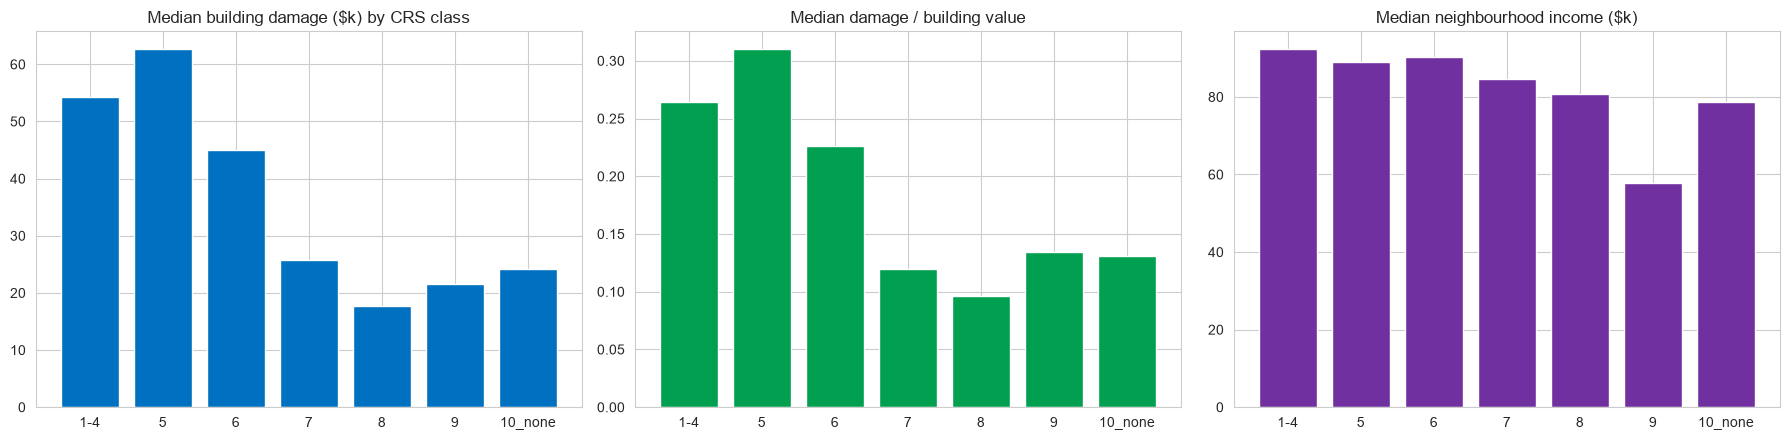

In [3]:
raw_table = data.groupby('crs_group').agg(claims=('id', 'size'), communities=('community', 'nunique'),
                                          median_damage=('buildingDamageAmount', 'median'), median_damage_ratio=('damage_ratio', 'median'),
                                          median_paid=('amountPaidOnBuildingClaim', 'median'), large_loss_pct=('large_loss_flag', 'mean'),
                                          median_income=('acs_median_household_income', 'median'), share_SFHA=('in_special_flood_hazard_area', 'mean'),
                                          median_coast_km=('coast_distance_km', 'median'), median_rain_3day=('rain_3day_mm', 'median'))
raw_table['large_loss_pct'] *= 100
raw_table = raw_table.reindex(['1-4', '5', '6', '7', '8', '9', '10_none']).round(3)
raw_table.to_csv(TABLE_DIR / '12_rq10_raw_by_class.csv')
print(raw_table.to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(raw_table.index, raw_table['median_damage'] / 1000, color='#0070C0'); axes[0].set_title('Median building damage ($k) by CRS class')
axes[1].bar(raw_table.index, raw_table['median_damage_ratio'], color='#00A050'); axes[1].set_title('Median damage / building value')
axes[2].bar(raw_table.index, raw_table['median_income'] / 1000, color='#7030A0'); axes[2].set_title('Median neighbourhood income ($k)')
plt.tight_layout(); plt.savefig(FIGURE_DIR / '12_rq10_raw_by_class.png', dpi=120); plt.show()

**How to read this.** The raw numbers point the **wrong way**: class 5 communities have a median damage of \$62,642 against \$24,216 in class 10, and a damage ratio of 0.31 against 0.13.

The reason is not CRS. These communities are coastal (median 2 km from the coast against 8 km), 95% inside the SFHA, and were hit by major hurricanes. A raw comparison mixes the CRS class with the hazard, so it cannot be read as an effect.

---
# Section 3: Propensity Scores (step by step)

1. **The propensity score** $e(x) = P(\text{treated} \mid x)$ is the chance that a claim comes from a better-CRS
   community, given its covariates. Rosenbaum & Rubin (1983) showed that if treatment depends only on $x$ ("no hidden
   confounders"), then comparing treated and control claims **with the same $e(x)$** removes the bias from $x$. One
   number replaces many covariates.
2. We estimate $e(x)$ with a **logistic regression** (Lecture 07) on the covariates plus state-year dummies.
3. **Overlap check.** If the model separates the two groups almost perfectly (ROC-AUC near 1), there are few comparable
   claims and any estimate depends on a small, unusual set of matches. We report a 5-fold **event-grouped**
   cross-validated ROC-AUC (mean and spread over folds).

Comparison sample (class 1-5 vs 10, state-years with both): 120,022 claims, treated 62,642, control 57,380, 102 state-years


Propensity model ROC-AUC, event-grouped 5-fold CV: 0.604 +/- 0.117 (folds [0.558 0.479 0.817 0.625 0.539]), 4 s


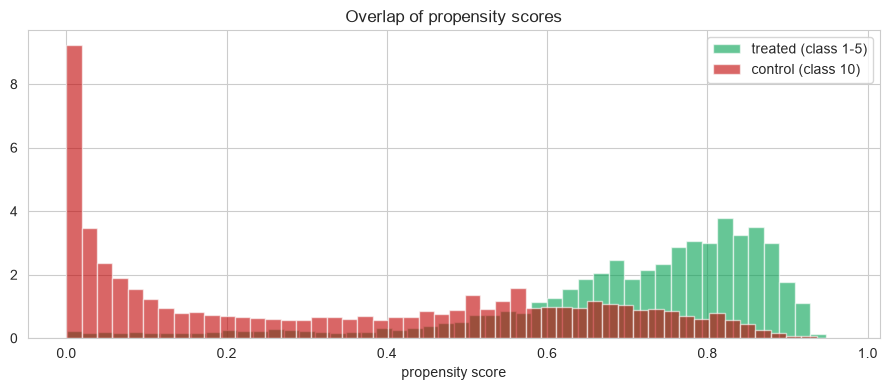

In [4]:
comparison = data[(data['crs_class'] <= 5) | (data['crs_class'] == 10)].copy()
comparison['treated'] = (comparison['crs_class'] <= 5).astype(int)
# Exact matching needs both groups in a state-year: keep only those strata.
stratum_mix = comparison.groupby('state_year')['treated'].agg(['min', 'max'])
mixed_strata = stratum_mix[(stratum_mix['min'] == 0) & (stratum_mix['max'] == 1)].index
comparison = comparison[comparison['state_year'].isin(mixed_strata)].reset_index(drop=True)
print(f'Comparison sample (class 1-5 vs 10, state-years with both): {len(comparison):,} claims, treated {comparison["treated"].sum():,}, '
      f'control {(comparison["treated"] == 0).sum():,}, {len(mixed_strata)} state-years')


def propensity_model():
    return Pipeline([('prep', make_preprocessor(COVARIATES, ['state_year'])),
                     ('logit', LogisticRegression(max_iter=3000, C=1.0))])


start = time.time()
cv_auc = []
for fit_index, validation_index in GroupKFold(n_splits=5).split(comparison, groups=comparison['event_group']):
    model = propensity_model().fit(comparison.iloc[fit_index], comparison['treated'].iloc[fit_index])
    cv_auc.append(roc_auc_score(comparison['treated'].iloc[validation_index], model.predict_proba(comparison.iloc[validation_index])[:, 1]))
propensity = propensity_model().fit(comparison, comparison['treated'])
comparison['propensity'] = propensity.predict_proba(comparison)[:, 1].clip(1e-4, 1 - 1e-4)
comparison['logit_propensity'] = np.log(comparison['propensity'] / (1 - comparison['propensity']))
print(f'Propensity model ROC-AUC, event-grouped 5-fold CV: {np.mean(cv_auc):.3f} +/- {np.std(cv_auc):.3f} (folds {np.round(cv_auc, 3)}), {time.time() - start:.0f} s')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(comparison.loc[comparison['treated'] == 1, 'propensity'], bins=50, alpha=0.6, density=True, label='treated (class 1-5)', color='#00A050')
ax.hist(comparison.loc[comparison['treated'] == 0, 'propensity'], bins=50, alpha=0.6, density=True, label='control (class 10)', color='#C00000')
ax.set_xlabel('propensity score'); ax.legend(); ax.set_title('Overlap of propensity scores')
plt.tight_layout(); plt.savefig(FIGURE_DIR / '12_rq10_propensity_overlap.png', dpi=120); plt.show()

---
# Section 4: Matching (nearest neighbour on the propensity score, Lecture 06)

1. For every treated claim, look **only inside its state-year** (exact matching).
2. Find the control claim with the closest logit propensity score (1 nearest neighbour, **with replacement**: one
   control may serve several treated claims).
3. Drop pairs farther apart than a **caliper** of 0.2 standard deviations of the logit score (Austin 2011).
4. The **average treatment effect on the treated (ATT)** is the mean of (treated outcome - matched control outcome).

**Balance check.** For each covariate we compute the **standardised mean difference** (SMD) =
(mean treated - mean control) / pooled SD. Before matching it shows how different the groups are; after matching
|SMD| < 0.1 is the usual rule for "balanced" (Austin 2011).

In [5]:
CALIPER = 0.2 * comparison['logit_propensity'].std()
treated_index, control_index = [], []
for stratum, group in comparison.groupby('state_year'):
    treated_rows = group[group['treated'] == 1]
    control_rows = group[group['treated'] == 0]
    neighbours = NearestNeighbors(n_neighbors=1).fit(control_rows[['logit_propensity']].values)
    distance, position = neighbours.kneighbors(treated_rows[['logit_propensity']].values)
    within = distance[:, 0] <= CALIPER
    treated_index.extend(treated_rows.index[within])
    control_index.extend(control_rows.index[position[within, 0]])
matched_treated = comparison.loc[treated_index].reset_index(drop=True)
matched_control = comparison.loc[control_index].reset_index(drop=True)
print(f'Matched pairs: {len(matched_treated):,} of {comparison["treated"].sum():,} treated claims '
      f'({len(matched_treated) / comparison["treated"].sum() * 100:.1f}%); distinct controls used: {len(set(control_index)):,}')


def standardised_difference(treated_values, control_values, control_weights=None):
    pooled_sd = np.sqrt((np.var(treated_values) + np.var(control_values)) / 2)
    control_mean = np.average(control_values, weights=control_weights)
    return (np.mean(treated_values) - control_mean) / pooled_sd if pooled_sd > 0 else 0.0


# IPW weights for the ATT: treated = 1, control = e / (1 - e), with the propensity trimmed to 0.01-0.99
trimmed = comparison['propensity'].clip(0.01, 0.99)
comparison['att_weight'] = np.where(comparison['treated'] == 1, 1.0, trimmed / (1 - trimmed))
treated_all = comparison[comparison['treated'] == 1]
control_all = comparison[comparison['treated'] == 0]
balance_rows = []
for covariate in COVARIATES + MEDIATOR_COVARIATES:
    balance_rows.append({'covariate': covariate, 'mean_treated': treated_all[covariate].mean(), 'mean_control': control_all[covariate].mean(),
                         'SMD_before': standardised_difference(treated_all[covariate], control_all[covariate]),
                         'SMD_after_matching': standardised_difference(matched_treated[covariate], matched_control[covariate]),
                         'SMD_after_IPW': standardised_difference(treated_all[covariate], control_all[covariate], control_all['att_weight'])})
balance_table = pd.DataFrame(balance_rows).round(3)
balance_table['used_in_propensity'] = balance_table['covariate'].isin(COVARIATES)
balance_table.to_csv(TABLE_DIR / '12_rq10_balance_table.csv', index=False)
print(balance_table.to_string(index=False))
print(f"\nCovariates with |SMD| > 0.1: before {int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_before'].abs() > 0.1).sum())}, after matching "
      f"{int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_after_matching'].abs() > 0.1).sum())}, after IPW "
      f"{int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_after_IPW'].abs() > 0.1).sum())} (of {len(COVARIATES)} used)")

Matched pairs: 62,625 of 62,642 treated claims (100.0%); distinct controls used: 15,372
                     covariate  mean_treated  mean_control  SMD_before  SMD_after_matching  SMD_after_IPW  used_in_propensity
                    log_income        11.437        11.315       0.272              -0.152         -0.089                True
                log_home_value        13.032        12.813       0.329              -0.081         -0.094                True
        acs_pct_owner_occupied        81.940        75.650       0.345              -0.012          0.023                True
         acs_median_year_built      1981.736      1978.050       0.260               0.011          0.077                True
         acs_pct_below_poverty         8.211        10.981      -0.329               0.095          0.034                True
    acs_pct_non_hispanic_white        81.943        68.034       0.607              -0.047         -0.011                True
   nri_inland_flood_risk_score

**How to read this.** Before matching, 19 of the 21 covariates have |SMD| > 0.1. The largest gaps are storm wind (SMD 1.03), storm category (1.00), community resilience score (-0.89), coastal flood risk (0.76) and share of non-Hispanic White residents (0.61).

After matching, 5 covariates are still above 0.1, and after IPW 2 are. Community resilience stays at about -0.19 in both, and income at -0.15 after matching. The balance is much better, but not perfect.

The propensity model has an event-grouped CV ROC-AUC of 0.60 +/- 0.12. Inside a state-year the groups overlap well, and 62,625 of 62,642 treated claims found a match within the caliper. But only 15,372 distinct controls are used, so some controls stand for many treated claims.

## 4.1 The matched effect, with event-block and community-block bootstrap intervals

Claims of one storm (and of one community) are not independent. So for the 95% interval we resample **whole events**
(500 repeats, the same idea as `event_block_bootstrap`), and, as a second check, whole **communities** (the level where
CRS is decided). The matched pairs are kept fixed; only the pairs that are drawn change.

In [6]:
def block_bootstrap_mean(differences, blocks, n_repeats=500, seed=SEED):
    rng = np.random.default_rng(seed)
    frame = pd.DataFrame({'difference': differences, 'block': blocks}).dropna()
    block_sums = frame.groupby('block')['difference'].agg(['sum', 'count'])
    sums, counts = block_sums['sum'].values, block_sums['count'].values
    draws = []
    for _ in range(n_repeats):
        chosen = rng.integers(0, len(sums), len(sums))
        draws.append(sums[chosen].sum() / counts[chosen].sum())
    return np.quantile(draws, 0.025), np.quantile(draws, 0.975), np.std(draws)


att_rows = []
for outcome, label in OUTCOMES.items():
    differences = matched_treated[outcome].astype(float) - matched_control[outcome].astype(float).values
    valid = differences.notna()
    event_low, event_high, event_sd = block_bootstrap_mean(differences[valid].values, matched_treated.loc[valid, 'event_group'].values)
    community_low, community_high, _ = block_bootstrap_mean(differences[valid].values, matched_treated.loc[valid, 'community'].values)
    att_rows.append({'outcome': label, 'pairs': int(valid.sum()), 'treated_mean': matched_treated.loc[valid, outcome].mean(),
                     'matched_control_mean': matched_control.loc[valid.values, outcome].mean(), 'ATT': differences[valid].mean(),
                     'event_CI_low': event_low, 'event_CI_high': event_high, 'event_bootstrap_SD': event_sd,
                     'community_CI_low': community_low, 'community_CI_high': community_high,
                     'raw_difference': treated_all[outcome].mean() - control_all[outcome].mean()})
att_table = pd.DataFrame(att_rows).round(4)
att_table.to_csv(TABLE_DIR / '12_rq10_psm_att.csv', index=False)
print(att_table.to_string(index=False))
print('\nFor the log outcomes, exp(ATT) - 1 is the percent difference:',
      {row['outcome']: f"{(np.exp(row['ATT']) - 1) * 100:+.1f}%" for _, row in att_table.iterrows() if row['outcome'].startswith('log')})

                  outcome  pairs  treated_mean  matched_control_mean     ATT  event_CI_low  event_CI_high  event_bootstrap_SD  community_CI_low  community_CI_high  raw_difference
      log building damage  62625       10.4040               10.3594  0.0446       -0.3809         0.2250              0.1498           -0.1024             0.2218          0.3633
  damage / building value  52166        0.3267                0.3184  0.0084       -0.0490         0.0355              0.0210           -0.0262             0.0369          0.0748
log(1 + building payment)  62625       10.2615               10.1970  0.0644       -0.4659         0.2892              0.1915           -0.1388             0.3022          0.6314
  large-loss flag (share)  62625        0.1655                0.2014 -0.0358       -0.0985         0.0505              0.0430           -0.0762             0.0176          0.0709

For the log outcomes, exp(ATT) - 1 is the percent difference: {'log building damage': '+4.6%', 'log(1 + 

**How to read this.** Matching shrinks the raw gap almost to zero.

- The raw log-damage gap is +0.36 (about 44% more damage in class 1-5). The matched ATT is **+0.045** (+4.6%), with an event-bootstrap 95% CI of [-0.38, +0.23] and a community-bootstrap CI of [-0.10, +0.22].
- The damage ratio ATT is +0.008 [-0.049, +0.036]. The payment ATT is +0.064 [-0.47, +0.29]. The large-loss share ATT is -0.036 [-0.099, +0.051].
- Every interval includes 0. The event intervals are wide because a few storms (Ian, Helene) dominate the treated group.

---
# Section 5: Inverse Probability Weighting (IPW)

Matching throws away unmatched controls. IPW keeps everyone and **re-weights** the controls so that they look like the
treated group: a control claim with propensity $e$ gets weight $e/(1-e)$ (it "stands for" treated claims that look like
it). Step by step: (1) the treated mean is a plain mean; (2) the control mean is the weighted mean with weights
$e/(1-e)$; (3) ATT = difference. Extreme weights make the estimate unstable, so the propensity is trimmed to 0.01-0.99.
The bootstrap resamples whole events (the propensity model is kept fixed, to keep the run short).

In [7]:
ipw_rows = []
rng = np.random.default_rng(SEED)
events = comparison['event_group'].unique()
rows_by_event = comparison.groupby('event_group').indices
for outcome, label in OUTCOMES.items():
    valid = comparison[outcome].notna().values
    y = comparison[outcome].astype(float).values
    treated_flag = comparison['treated'].values == 1
    weights = comparison['att_weight'].values

    def ipw_att(index):
        index = index[valid[index]]
        t = index[treated_flag[index]]
        c = index[~treated_flag[index]]
        return y[t].mean() - np.average(y[c], weights=weights[c])

    point = ipw_att(np.arange(len(comparison)))
    draws = []
    for _ in range(300):
        chosen = rng.choice(events, len(events), replace=True)
        index = np.concatenate([rows_by_event[event] for event in chosen])
        if treated_flag[index].any() and (~treated_flag[index]).any():
            draws.append(ipw_att(index))
    ipw_rows.append({'outcome': label, 'ATT_IPW': point, 'event_CI_low': np.quantile(draws, 0.025), 'event_CI_high': np.quantile(draws, 0.975),
                     'event_bootstrap_SD': np.std(draws)})
ipw_table = pd.DataFrame(ipw_rows).round(4)
ipw_table['effective_control_sample'] = round(control_all['att_weight'].sum() ** 2 / (control_all['att_weight'] ** 2).sum())
ipw_table.to_csv(TABLE_DIR / '12_rq10_ipw_att.csv', index=False)
print(ipw_table.to_string(index=False))

                  outcome  ATT_IPW  event_CI_low  event_CI_high  event_bootstrap_SD  effective_control_sample
      log building damage  -0.0114       -0.0940         0.1327              0.0615                     18777
  damage / building value  -0.0054       -0.0220         0.0215              0.0121                     18777
log(1 + building payment)   0.0014       -0.0960         0.2647              0.0893                     18777
  large-loss flag (share)  -0.0292       -0.0662         0.0177              0.0243                     18777


---
# Section 6: Fixed-Effects Regression, All Classes, and the Class-5 Threshold Test

A different strategy: a **linear regression** of the outcome on CRS-class dummies (class 10 = reference) and the
covariates, with **fixed effects**. A fixed effect is a separate intercept for each group:
- **FE1:** state and loss-year fixed effects: compare claims within the same state and year;
- **FE2:** state and **event** fixed effects: compare claims hit by **the same storm** in the same state;
- **FE3:** FE2 + the possible mediators (elevated, post-FIRM, coverage), a sensitivity check.
Standard errors are clustered by **community** (CRS is a community decision).

**Class-5 threshold test (Frimpong et al.).** If CRS works only from class 5, the class-5 coefficient should be clearly
more negative than class 6 (Wald test: class 5 = class 6), and classes 6-9 should be close to 0.

In [8]:
data['crs_group'] = pd.Categorical(data['crs_group'], categories=['10_none', '1-4', '5', '6', '7', '8', '9'])
COVARIATE_TERMS = ' + '.join(COVARIATES)
FE_SPECS = {'FE1: state + year': f'{COVARIATE_TERMS} + C(state) + C(loss_year)',
            'FE2: state + event': f'{COVARIATE_TERMS} + C(state) + C(event_group)',
            'FE3: FE2 + mediators': f'{COVARIATE_TERMS} + ' + ' + '.join(MEDIATOR_COVARIATES) + ' + C(state) + C(event_group)'}
fe_rows, threshold_rows = [], []
for outcome in ['log_damage', 'log_paid', 'damage_ratio']:
    for spec_name, terms in FE_SPECS.items():
        rows_used = data.dropna(subset=[outcome] + (MEDIATOR_COVARIATES if 'FE3' in spec_name else []))
        result = smf.ols(f'{outcome} ~ C(crs_group) + {terms}', data=rows_used).fit(
            cov_type='cluster', cov_kwds={'groups': pd.factorize(rows_used['community'])[0]})
        for level in ['1-4', '5', '6', '7', '8', '9']:
            term = f'C(crs_group)[T.{level}]'
            low, high = result.conf_int().loc[term]
            fe_rows.append({'outcome': outcome, 'model': spec_name, 'class': level, 'coefficient': result.params[term], 'ci_low': low,
                            'ci_high': high, 'p_value': result.pvalues[term], 'claims': int(result.nobs)})
        wald = result.t_test('C(crs_group)[T.5] - C(crs_group)[T.6] = 0')
        threshold_rows.append({'outcome': outcome, 'model': spec_name, 'class5_minus_class6': float(np.squeeze(wald.effect)),
                               'p_value': float(np.squeeze(wald.pvalue))})
fe_table = pd.DataFrame(fe_rows).round(4)
threshold_table = pd.DataFrame(threshold_rows).round(4)
fe_table.to_csv(TABLE_DIR / '12_rq10_fixed_effects.csv', index=False)
threshold_table.to_csv(TABLE_DIR / '12_rq10_class5_threshold_test.csv', index=False)
print(fe_table[fe_table['outcome'] == 'log_damage'].to_string(index=False))
print('\nClass-5 threshold test (Wald, class 5 - class 6):'); print(threshold_table.to_string(index=False))

   outcome                model class  coefficient  ci_low  ci_high  p_value  claims
log_damage    FE1: state + year   1-4      -0.1216 -0.3246   0.0814   0.2403  188562
log_damage    FE1: state + year     5      -0.0180 -0.1797   0.1437   0.8271  188562
log_damage    FE1: state + year     6      -0.0481 -0.2188   0.1227   0.5812  188562
log_damage    FE1: state + year     7       0.0025 -0.1803   0.1852   0.9789  188562
log_damage    FE1: state + year     8      -0.1629 -0.3482   0.0224   0.0849  188562
log_damage    FE1: state + year     9       0.0162 -0.1700   0.2023   0.8648  188562
log_damage   FE2: state + event   1-4      -0.1340 -0.3190   0.0510   0.1558  188562
log_damage   FE2: state + event     5       0.0238 -0.1423   0.1900   0.7785  188562
log_damage   FE2: state + event     6      -0.0795 -0.2491   0.0901   0.3582  188562
log_damage   FE2: state + event     7      -0.0420 -0.2010   0.1170   0.6045  188562
log_damage   FE2: state + event     8      -0.1549 -0.3160   0.00

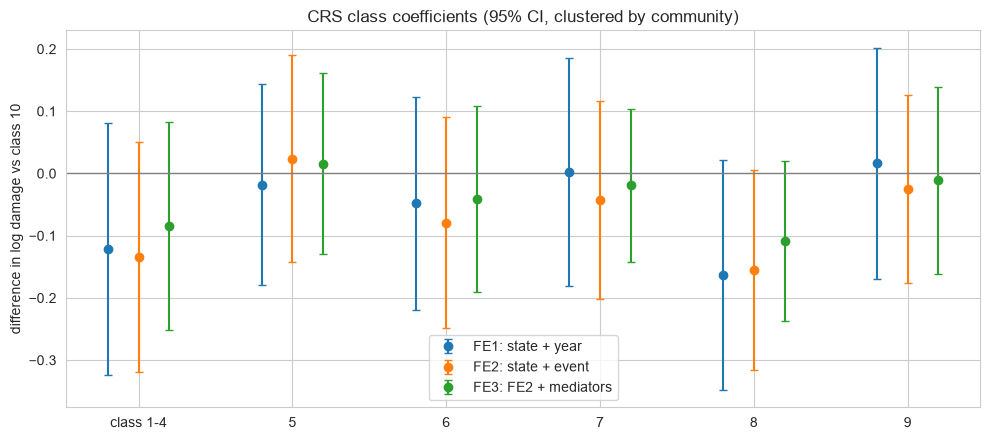

In [9]:
plot_rows = fe_table[(fe_table['outcome'] == 'log_damage')]
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, (spec_name, group) in zip([-0.2, 0, 0.2], plot_rows.groupby('model', sort=False)):
    positions = np.arange(len(group)) + offset
    ax.errorbar(positions, group['coefficient'], yerr=[group['coefficient'] - group['ci_low'], group['ci_high'] - group['coefficient']],
                fmt='o', capsize=3, label=spec_name)
ax.axhline(0, color='grey', lw=1); ax.set_xticks(range(6)); ax.set_xticklabels(['class 1-4', '5', '6', '7', '8', '9'])
ax.set_ylabel('difference in log damage vs class 10'); ax.legend(); ax.set_title('CRS class coefficients (95% CI, clustered by community)')
plt.tight_layout(); plt.savefig(FIGURE_DIR / '12_rq10_fixed_effects.png', dpi=120); plt.show()

**How to read this (IPW and fixed effects).**

- **IPW** gives the same picture as matching: an ATT on log damage of -0.011 [-0.094, +0.133] and on log payment of +0.001 [-0.096, +0.265].
- **Fixed-effects regression:** no CRS class differs clearly from class 10. Class 5 vs 10 is -0.018 [-0.180, +0.144] in FE1, +0.024 [-0.142, +0.190] in FE2 (same storm) and +0.016 [-0.130, +0.161] in FE3. Classes 1-4 and 8 have negative point estimates (-0.13 and -0.15 in FE2), with p = 0.16 and p = 0.06.
- **Class-5 threshold test:** the class 5 - class 6 difference is +0.10 (p = 0.26) for log damage in FE2. It has the wrong sign for a "class 5 works" effect and is not significant for any outcome or model (p >= 0.18). So we **do not** reproduce Frimpong et al.'s class-5 threshold.

---
# Section 7: Within-Community Changes (community fixed effects)

The strongest comparison uses the **same community** before and after its class changed: everything fixed about the
community (location, wealth, building stock) cancels out. Only about 4% of communities changed class during 2020-2025,
so this estimate is noisy. We use the **within transformation**: subtract each community's mean from the outcome and
from every variable, then run OLS (this is identical to adding one dummy per community).

In [10]:
data['better_crs'] = (data['crs_class'] <= 5).astype(int)
data['middle_crs'] = data['crs_class'].between(6, 9).astype(int)
year_dummies = pd.get_dummies(data['loss_year'], prefix='year', drop_first=True).astype(float)
within_columns = ['log_damage', 'better_crs', 'middle_crs'] + COVARIATES
within = pd.concat([data[within_columns], year_dummies], axis=1)
within = within - within.groupby(data['community']).transform('mean')
changers = data.groupby('community')['crs_class'].nunique()
within_formula = 'log_damage ~ better_crs + middle_crs + ' + ' + '.join(COVARIATES + list(year_dummies.columns)) + ' - 1'
within_result = smf.ols(within_formula, data=within).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(data['community'])[0]})
community_fe = {name: (within_result.params[name], *within_result.conf_int().loc[name], within_result.pvalues[name]) for name in ['better_crs', 'middle_crs']}
claims_in_changers = data['community'].map(changers).gt(1).sum()
print(f'Communities that changed class: {int((changers > 1).sum())} of {len(changers):,}; their claims: {claims_in_changers:,}')
for name, (coef, low, high, p) in community_fe.items():
    print(f'{name}: {coef:+.3f} [{low:+.3f}, {high:+.3f}], p = {p:.3f}')

Communities that changed class: 247 of 6,440; their claims: 38,506
better_crs: +0.336 [-0.079, +0.751], p = 0.113
middle_crs: +0.210 [+0.016, +0.404], p = 0.033


---
# Section 8: Stability: Training Years vs Test Years

The project's time split is used here as a stability check: the matching estimate is computed separately for 2020-2023
and 2024-2025 (same propensity model, pairs split by year).

In [11]:
period_rows = []
for period_name, years in [('2020-2023', TRAIN_YEARS), ('2024-2025', TEST_YEARS)]:
    in_period = matched_treated['loss_year'].isin(years).values
    for outcome in ['log_damage', 'log_paid']:
        differences = (matched_treated.loc[in_period, outcome].values - matched_control.loc[in_period, outcome].values)
        low, high, _ = block_bootstrap_mean(differences, matched_treated.loc[in_period, 'event_group'].values)
        period_rows.append({'period': period_name, 'outcome': outcome, 'pairs': int(in_period.sum()), 'ATT': differences.mean(),
                            'event_CI_low': low, 'event_CI_high': high})
period_table = pd.DataFrame(period_rows).round(4)
period_table.to_csv(TABLE_DIR / '12_rq10_att_by_period.csv', index=False)
print(period_table.to_string(index=False))

   period    outcome  pairs    ATT  event_CI_low  event_CI_high
2020-2023 log_damage  30376 0.0919       -0.1361         0.3103
2020-2023   log_paid  30376 0.1311       -0.2295         0.4446
2024-2025 log_damage  32249 0.0001       -0.6403         0.2512
2024-2025   log_paid  32249 0.0016       -0.7338         0.3154


**How to read this (Sections 7 and 8).**

- **Within-community changes:** only 247 of the 6,440 communities changed class (38,506 claims). Moving into class 1-5 goes with +0.34 log damage [-0.08, +0.75], which is not significant. Moving into the middle classes (6-8) goes with +0.21 [+0.02, +0.40], p = 0.03. That is a *positive* coefficient, against the expected direction, and with so few switchers it is more likely noise or a change in the storm mix than an effect.
- **By period:** the matched ATT is +0.09 [-0.14, +0.31] in 2020-2023 and +0.00 [-0.64, +0.25] in 2024-2025. It is near 0 in both periods.

---
# Section 9: Leakage, Confounding and What We Cannot Claim

- **No predictive leakage problem, but "bad controls".** Outcomes (damage, payment) are never covariates. The real risk
  is controlling for things CRS itself changes (elevation, building standards, coverage). The main models leave them
  out; FE3 shows what happens if they are added.
- **Hidden confounders.** Propensity methods only remove bias from **measured** covariates. Local building-code
  enforcement, drainage systems, or a strong local floodplain office can affect losses and the CRS class at the same time.
- **Florida dominates the treated group.** Most class 1-5 claims are in Florida, so the result is mostly a Florida
  comparison (exact matching on state and year makes that explicit).
- **We only see claims.** CRS can reduce losses by preventing claims altogether (fewer homes flooded) and by changing
  who buys insurance (discounts raise take-up, Frimpong et al.). A claims-only analysis measures the **severity** of
  claims that happened, not the number of avoided claims.
- **The class is the class used to rate the policy**, which can lag behind the community's current class.

---
## The numbers behind the answer

In [12]:
def att_text(table, outcome_label, estimate_column):
    row = table[table['outcome'] == outcome_label].iloc[0]
    return f"{row[estimate_column]:+.4f} [{row['event_CI_low']:+.4f}, {row['event_CI_high']:+.4f}]"


def fe_text(outcome, model, level):
    row = fe_table[(fe_table['outcome'] == outcome) & (fe_table['model'] == model) & (fe_table['class'] == level)].iloc[0]
    return f"{row['coefficient']:+.4f} [{row['ci_low']:+.4f}, {row['ci_high']:+.4f}], p = {row['p_value']:.3f}"


psm_damage = att_table[att_table['outcome'] == 'log building damage'].iloc[0]
rows = [
    ('claims in analysis (residential, damage > 0)', len(data), 'Section 1'),
    ('claims class 1-5 / 6-9 / 10', f"{(data['crs_class'] <= 5).sum():,} / {data['crs_class'].between(6, 9).sum():,} / {(data['crs_class'] == 10).sum():,}", 'Section 1'),
    ('share of class 1-5 claims in Florida (%)', (data.loc[data['crs_class'] <= 5, 'state'] == 'FL').mean() * 100, 'Section 1'),
    ('raw median damage class 5 vs class 10 ($)', f"{raw_table.loc['5', 'median_damage']:,.0f} vs {raw_table.loc['10_none', 'median_damage']:,.0f}", '12_rq10_raw_by_class'),
    ('propensity ROC-AUC, event-grouped CV (mean +/- SD)', f"{np.mean(cv_auc):.3f} +/- {np.std(cv_auc):.3f}", 'Section 3'),
    ('matched pairs (% of treated)', f"{len(matched_treated):,} ({len(matched_treated) / comparison['treated'].sum() * 100:.1f}%)", 'Section 4'),
    ('covariates |SMD| > 0.1: before / after matching / after IPW', f"{int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_before'].abs() > 0.1).sum())} / {int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_after_matching'].abs() > 0.1).sum())} / {int((balance_table.loc[balance_table['used_in_propensity'], 'SMD_after_IPW'].abs() > 0.1).sum())}", '12_rq10_balance_table'),
    ('raw difference in log damage (treated - control)', psm_damage['raw_difference'], '12_rq10_psm_att'),
    ('PSM ATT log damage [event 95% CI]', att_text(att_table, 'log building damage', 'ATT'), '12_rq10_psm_att'),
    ('PSM ATT log damage [community 95% CI]', f"{psm_damage['ATT']:+.4f} [{psm_damage['community_CI_low']:+.4f}, {psm_damage['community_CI_high']:+.4f}]", '12_rq10_psm_att'),
    ('PSM ATT log damage as % difference', f"{(np.exp(psm_damage['ATT']) - 1) * 100:+.1f}%", '12_rq10_psm_att'),
    ('PSM ATT damage ratio [event 95% CI]', att_text(att_table, 'damage / building value', 'ATT'), '12_rq10_psm_att'),
    ('PSM ATT log(1 + payment) [event 95% CI]', att_text(att_table, 'log(1 + building payment)', 'ATT'), '12_rq10_psm_att'),
    ('PSM ATT large-loss share [event 95% CI]', att_text(att_table, 'large-loss flag (share)', 'ATT'), '12_rq10_psm_att'),
    ('IPW ATT log damage [event 95% CI]', att_text(ipw_table, 'log building damage', 'ATT_IPW'), '12_rq10_ipw_att'),
    ('IPW ATT log(1 + payment) [event 95% CI]', att_text(ipw_table, 'log(1 + building payment)', 'ATT_IPW'), '12_rq10_ipw_att'),
    ('FE1 log damage, class 5 vs 10', fe_text('log_damage', 'FE1: state + year', '5'), '12_rq10_fixed_effects'),
    ('FE2 log damage, class 5 vs 10 (same storm)', fe_text('log_damage', 'FE2: state + event', '5'), '12_rq10_fixed_effects'),
    ('FE2 log damage, class 6 vs 10', fe_text('log_damage', 'FE2: state + event', '6'), '12_rq10_fixed_effects'),
    ('FE2 log damage, class 1-4 vs 10', fe_text('log_damage', 'FE2: state + event', '1-4'), '12_rq10_fixed_effects'),
    ('FE3 log damage, class 5 vs 10 (+ mediators)', fe_text('log_damage', 'FE3: FE2 + mediators', '5'), '12_rq10_fixed_effects'),
    ('FE2 log payment, class 5 vs 10', fe_text('log_paid', 'FE2: state + event', '5'), '12_rq10_fixed_effects'),
    ('threshold test FE2 log damage: class 5 - class 6 (p)', f"{threshold_table.iloc[1]['class5_minus_class6']:+.4f} (p = {threshold_table.iloc[1]['p_value']:.3f})", '12_rq10_class5_threshold_test'),
    ('community FE: class 1-5 vs 10, log damage', f"{community_fe['better_crs'][0]:+.3f} [{community_fe['better_crs'][1]:+.3f}, {community_fe['better_crs'][2]:+.3f}], p = {community_fe['better_crs'][3]:.3f}", 'Section 7'),
    ('PSM ATT log damage 2020-2023 / 2024-2025', ' / '.join(f"{r['ATT']:+.3f} [{r['event_CI_low']:+.3f}, {r['event_CI_high']:+.3f}]" for _, r in period_table[period_table['outcome'] == 'log_damage'].iterrows()), '12_rq10_att_by_period'),
]
answer_numbers = show_answer_numbers(rows, '12_rq10')
print(f'\nNotebook run time: {(time.time() - notebook_start) / 60:.1f} min')

                                                   quantity                                             value                        source
               claims in analysis (residential, damage > 0)                                            188562                     Section 1
                                claims class 1-5 / 6-9 / 10                          62,646 / 34,350 / 91,566                     Section 1
                   share of class 1-5 claims in Florida (%)                                           95.5193                     Section 1
                  raw median damage class 5 vs class 10 ($)                                  62,642 vs 24,216          12_rq10_raw_by_class
         propensity ROC-AUC, event-grouped CV (mean +/- SD)                                   0.604 +/- 0.117                     Section 3
                               matched pairs (% of treated)                                   62,625 (100.0%)                     Section 4
covariates |SMD| > 0

---
# Research Question -> Answer

**Research question (RQ10):** Do claims from communities with a better Community Rating System class (1-5) have lower building damage or payments than comparable claims from non-CRS communities (class 10)? Is there a threshold at class 5?

**Answer (from the numbers above).**

1. **The raw gap is confounded.** Class 1-5 claims have about 2.6 times the median damage of class 10 claims (\$62,642 vs \$24,216), because they are coastal Florida homes hit by major hurricanes (95.5% of class 1-5 claims are in Florida).
2. **No clear effect after adjustment.** Matched within state-year: the log-damage ATT is +0.045 [event CI -0.38, +0.23; community CI -0.10, +0.22]. IPW gives -0.011 [-0.094, +0.133]. Same-storm fixed effects give +0.024 for class 5 [-0.142, +0.190]. Payments and the large-loss share also show no effect.
3. **No class-5 threshold.** The class 5 - class 6 difference is +0.10 (p = 0.26), and no Wald test is significant.
4. **Few switchers.** Within-community estimates are noisy (247 communities changed class) and do not show a reduction.
5. **Balance is good but imperfect.** 19 of 21 covariates are unbalanced before matching, 5 after; community resilience stays at SMD about -0.19.

**Bottom line:** in 2020-2025 claims, we find **no measurable difference** in damage per claim between better-CRS and non-CRS communities hit by the same storms. The intervals are wide enough to hide a moderate effect of about +/-20%.

This does not show that CRS fails, for three reasons:

- CRS mainly works by preventing claims (fewer flooded buildings) and by lowering premiums, which claim-level data cannot see;
- the treated group is almost only Florida;
- unmeasured confounders (building codes, local drainage) remain.

Published CRS studies (Highfield & Brody 2013; Gourevitch & Pinter 2023) measure community-level outcomes such as total
losses or claims, which is a different outcome from the damage per claim measured here.

**References for this notebook.**
- Gourevitch, J. D. & Pinter, N. (2023). Federal incentives for community-level climate adaptation: an evaluation of FEMA's Community Rating System. *Environmental Research Letters* 18, 034037. https://doi.org/10.1088/1748-9326/acbaae
- Frimpong, E., Petrolia, D. R., Harri, A. & Cartwright, J. H. (2020). Flood insurance and claims: The impact of the Community Rating System. *Applied Economic Perspectives and Policy* 42(2), 245-262 (online 2019). https://doi.org/10.1093/aepp/ppz013
- Highfield, W. E. & Brody, S. D. (2013). Evaluating the effectiveness of local mitigation activities in reducing flood losses. *Natural Hazards Review* 14(4), 229-236. https://doi.org/10.1061/(ASCE)NH.1527-6996.0000114
- Rosenbaum, P. R. & Rubin, D. B. (1983). The central role of the propensity score in observational studies for causal effects. *Biometrika* 70(1), 41-55.
- Austin, P. C. (2011). An introduction to propensity score methods for reducing the effects of confounding in observational studies. *Multivariate Behavioral Research* 46(3), 399-424.
- FEMA. *Community Rating System*. https://www.fema.gov/floodplain-management/community-rating-system
- FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3* (data dictionary: `crsClassCode`, `nfipRatedCommunityNumber`). https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3